# Downsampling verification

Sanity checks for the **in-code depth downsampling** (`features.py --target_coverage` /
`--downsample_frac`, applied in `util.get_filtered_alignments` via an MD5 hash of the
seed-salted read name). Run this after `slurm/extract_features_downsampled.sh` has
produced at least one run under `extracted_features/downsampled/`.

The downsampling is *file-wide*: one keep/drop decision per fragment, independent of
position — as if the sample had been sequenced shallower. If that is true, four things
must hold, each checked below:

1. **Per-sample totals** — the achieved fraction of (GC-weighted) fragments equals the
   intended per-sample fraction recorded in `downsample_log/`, up to binomial noise.
2. **Per-locus uniformity** — every bin is thinned by the *same* fraction: downsampled
   per-bin counts scatter around `fraction x full` with no positional structure.
3. **Coverage profiles** — along a chromosome, the downsampled profile is a vertically
   scaled copy of the full-depth profile (same shape, more noise).
4. **Fragment-length distribution** — thinning is length-unbiased, so the *normalized*
   length distribution is unchanged.

Checks 5–7 then move from raw counts to the **five per-TSS metrics the classifier
actually consumes** (`fslr_coverage`, `fslr`, `griffin_diff`, `rcov`, `mwh`): how well
each metric is preserved per locus (5), how that preservation varies across samples (6),
and whether the metric *distributions* shift at lower depth (7). Unlike counts, these
ratio/shape metrics are **not** expected to be identical after thinning — they get
noisier as depth falls, which is exactly the effect the robustness experiment measures.
What must NOT appear is a systematic bias beyond what binomial thinning explains.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- Config -------------------------------------------------------------
# Repo root: walk up until pyproject.toml is found (works from notebooks/)
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

BED_NAME = "biomart_10kb"          # bed set to verify: "biomart_10kb" or "zhu_all_after_lift"
MAX_SAMPLES = 6                     # samples to load per run (keeps IO manageable)
PROFILE_CHROM = "chr1"             # chromosome for the coverage-profile overlay

FULL_DIR = REPO_ROOT / "extracted_features" / BED_NAME
DS_ROOT = REPO_ROOT / "extracted_features" / "downsampled"

LEN_COLS = [str(l) for l in range(100, 221)]
META_COLS = ["chrom", "start", "end", "absolute_fragment_counts",
             "absolute_short_fragments", "absolute_long_fragments",
             "mean_coverage", "fslr"]
# The five per-TSS metrics the classifier consumes: model_hpc.py reads exactly
# these columns from the BIN csvs (checks 5-7 compare them across depths).
FEATURE_COLS = ["fslr_coverage", "fslr", "griffin_diff", "rcov", "mwh"]


def sample_from_stem(stem):
    """'EE85754.hg38.frag.tsv_BIN' -> 'EE85754' (same stripping as compute_mean_coverage)."""
    s = stem.removesuffix("_BIN").removesuffix("_NOGC_BIN")
    return s.removesuffix(".hg38.frag.tsv")


def load_bin(path):
    df = pd.read_csv(path, usecols=lambda c: c in META_COLS or c in LEN_COLS or c in FEATURE_COLS)
    return df


print(f"Repo root : {REPO_ROOT}")
print(f"Full-depth: {FULL_DIR}")
print(f"Runs root : {DS_ROOT}")

Repo root : U:\KWFcfDNA\emc\comp
Full-depth: U:\KWFcfDNA\emc\comp\extracted_features\biomart_10kb
Runs root : U:\KWFcfDNA\emc\comp\extracted_features\downsampled


In [2]:
# --- Discover downsampling runs and load shared samples ------------------
runs = {}
if DS_ROOT.is_dir():
    for run_dir in sorted(DS_ROOT.iterdir()):
        bed_dir = run_dir / BED_NAME
        log_dir = run_dir / "downsample_log"
        if not bed_dir.is_dir() or not log_dir.is_dir():
            continue
        # intended per-sample fraction from the extraction's own log
        fractions = {}
        for log_file in log_dir.glob("*.csv"):
            row = pd.read_csv(log_file).iloc[0]
            fractions[str(row["sample_name"])] = float(row["downsample_frac"])
        ds_files = sorted(bed_dir.glob("*_BIN.csv"))
        shared = [f for f in ds_files if (FULL_DIR / f.name).exists()][:MAX_SAMPLES]
        if shared:
            runs[run_dir.name] = {"files": shared, "fractions": fractions}

if not runs:
    print("No downsampled runs with matching full-depth features found yet.")
    print(f"Expected layout: {DS_ROOT}/<run>/{BED_NAME}/<sample>_BIN.csv + <run>/downsample_log/")
    print("Run slurm/extract_features_downsampled.sh first, then re-run this notebook.")
else:
    full_cache = {}
    data = {}
    for run_name, info in runs.items():
        data[run_name] = {}
        for f in info["files"]:
            sample = sample_from_stem(f.stem)
            if f.name not in full_cache:
                full_cache[f.name] = load_bin(FULL_DIR / f.name)
            data[run_name][sample] = {
                "ds": load_bin(f),
                "full": full_cache[f.name],
                "frac": info["fractions"].get(sample, np.nan),
            }
        loaded = ", ".join(data[run_name])
        print(f"{run_name}: {len(data[run_name])} samples loaded ({loaded})")


cov0.1x_seed42: 6 samples loaded (EE87786, EE87787, EE87788, EE87789, EE87790, EE87791)


cov1x_seed42: 6 samples loaded (EE87786, EE87787, EE87788, EE87789, EE87790, EE87791)


## Check 1 — per-sample achieved vs intended fraction

The achieved fraction is the ratio of total (GC-weighted) fragment counts,
`sum(ds) / sum(full)` over all bins. With millions of fragments per sample the binomial
standard error is far below 1%, so points must sit on the identity line. Samples whose
native coverage was below the target are kept in full (`fraction = 1.0`) and must sit
exactly at (1, 1).


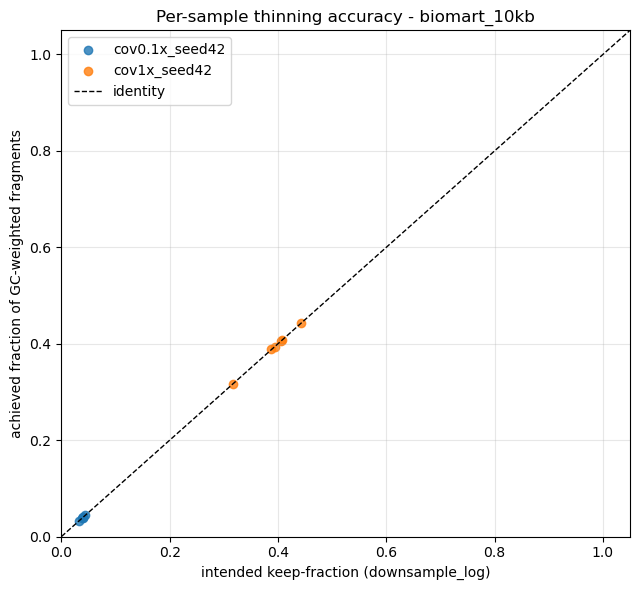

           run  sample  intended  achieved  rel_error_pct
cov0.1x_seed42 EE87788    0.0388    0.0390         0.5481
cov0.1x_seed42 EE87791    0.0406    0.0404        -0.2907
cov0.1x_seed42 EE87789    0.0442    0.0441        -0.2829
cov0.1x_seed42 EE87787    0.0407    0.0408         0.1548
cov0.1x_seed42 EE87786    0.0394    0.0395         0.1415
  cov1x_seed42 EE87787    0.4069    0.4074         0.1248
  cov1x_seed42 EE87788    0.3879    0.3883         0.1028
cov0.1x_seed42 EE87790    0.0317    0.0317         0.0864
  cov1x_seed42 EE87791    0.4056    0.4054        -0.0573
  cov1x_seed42 EE87786    0.3939    0.3941         0.0467
  cov1x_seed42 EE87789    0.4424    0.4423        -0.0089
  cov1x_seed42 EE87790    0.3166    0.3165        -0.0085

Worst relative error: 0.548% (OK, consistent with binomial noise)


In [3]:
if runs:
    fig, ax = plt.subplots(figsize=(6.5, 6))
    rows = []
    for run_name, samples in data.items():
        xs, ys = [], []
        for sample, d in samples.items():
            intended = d["frac"]
            achieved = d["ds"]["absolute_fragment_counts"].sum() / d["full"]["absolute_fragment_counts"].sum()
            xs.append(intended); ys.append(achieved)
            rows.append({"run": run_name, "sample": sample, "intended": intended,
                         "achieved": achieved,
                         "rel_error_pct": 100 * (achieved / intended - 1) if intended > 0 else np.nan})
        ax.scatter(xs, ys, alpha=0.8, label=run_name)
    lim = [0, 1.05]
    ax.plot(lim, lim, "k--", lw=1, label="identity")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("intended keep-fraction (downsample_log)")
    ax.set_ylabel("achieved fraction of GC-weighted fragments")
    ax.set_title(f"Per-sample thinning accuracy - {BED_NAME}")
    ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    check1 = pd.DataFrame(rows).sort_values("rel_error_pct", key=abs, ascending=False)
    print(check1.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    worst = check1["rel_error_pct"].abs().max()
    print(f"\nWorst relative error: {worst:.3f}% "
          f"({'OK, consistent with binomial noise' if worst < 1 else 'INVESTIGATE - larger than sampling noise'})")


## Check 2 — per-locus uniformity (file-wide, not per-window)

Left: per-bin downsampled counts against `fraction x full` counts; a tight identity-line
scatter means every bin was thinned equally. Right: standardized residuals
`(ds - f*full) / sqrt(f*(1-f)*full)` along the genome — a flat band around 0 with spread
~1 and no chromosome- or position-dependent structure rules out positional bias.
(Residuals are approximate: GC weights make counts non-integer, slightly inflating spread.)


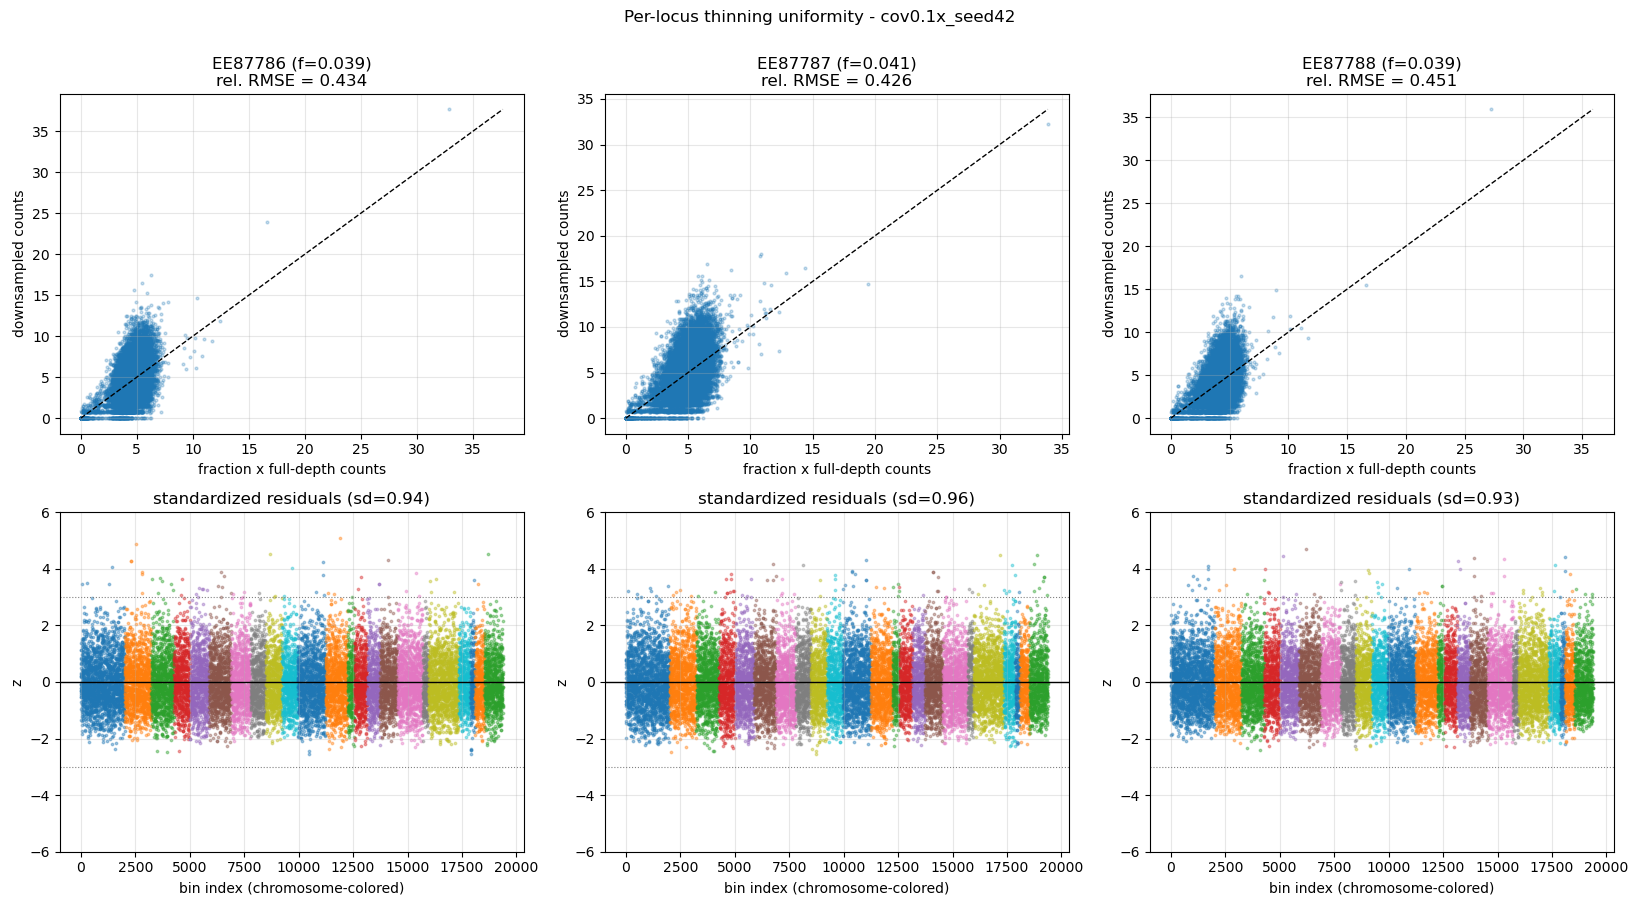

In [4]:
if runs:
    run_name = next(iter(data))
    samples = list(data[run_name])[:3]
    fig, axes = plt.subplots(2, len(samples), figsize=(5.5 * len(samples), 9), squeeze=False)
    for j, sample in enumerate(samples):
        d = data[run_name][sample]
        f, full_n, ds_n = d["frac"], d["full"]["absolute_fragment_counts"].values, d["ds"]["absolute_fragment_counts"].values
        expected = f * full_n

        ax = axes[0][j]
        ax.scatter(expected, ds_n, s=4, alpha=0.25, rasterized=True)
        m = max(expected.max(), ds_n.max())
        ax.plot([0, m], [0, m], "k--", lw=1)
        rel_rmse = np.sqrt(np.mean((ds_n - expected) ** 2)) / max(expected.mean(), 1e-9)
        ax.set_title(f"{sample} (f={f:.3f})\nrel. RMSE = {rel_rmse:.3f}")
        ax.set_xlabel("fraction x full-depth counts"); ax.set_ylabel("downsampled counts")
        ax.grid(alpha=0.3)

        ax = axes[1][j]
        with np.errstate(divide="ignore", invalid="ignore"):
            z = (ds_n - expected) / np.sqrt(np.clip(f * (1 - f) * full_n, 1e-9, None))
        z = np.where(full_n > 0, z, np.nan)
        chroms = d["full"]["chrom"].values
        for c, chrom in enumerate(pd.unique(chroms)):
            idx = np.flatnonzero(chroms == chrom)
            ax.scatter(idx, z[idx], s=3, alpha=0.4, color=f"C{c % 10}", rasterized=True)
        ax.axhline(0, color="k", lw=1)
        for band in (-3, 3):
            ax.axhline(band, color="grey", lw=0.8, ls=":")
        ax.set_ylim(-6, 6)
        ax.set_title(f"standardized residuals (sd={np.nanstd(z):.2f})")
        ax.set_xlabel("bin index (chromosome-colored)"); ax.set_ylabel("z")
        ax.grid(alpha=0.3)
    fig.suptitle(f"Per-locus thinning uniformity - {run_name}", y=1.0)
    plt.tight_layout(); plt.show()


## Check 3 — coverage profile along a chromosome

The downsampled per-bin mean coverage should be a vertically scaled copy of the
full-depth profile. Plotting full-depth `x fraction` on top of the downsampled profile:
the two traces must coincide (downsampled = noisier, but no shape change, no dropouts).


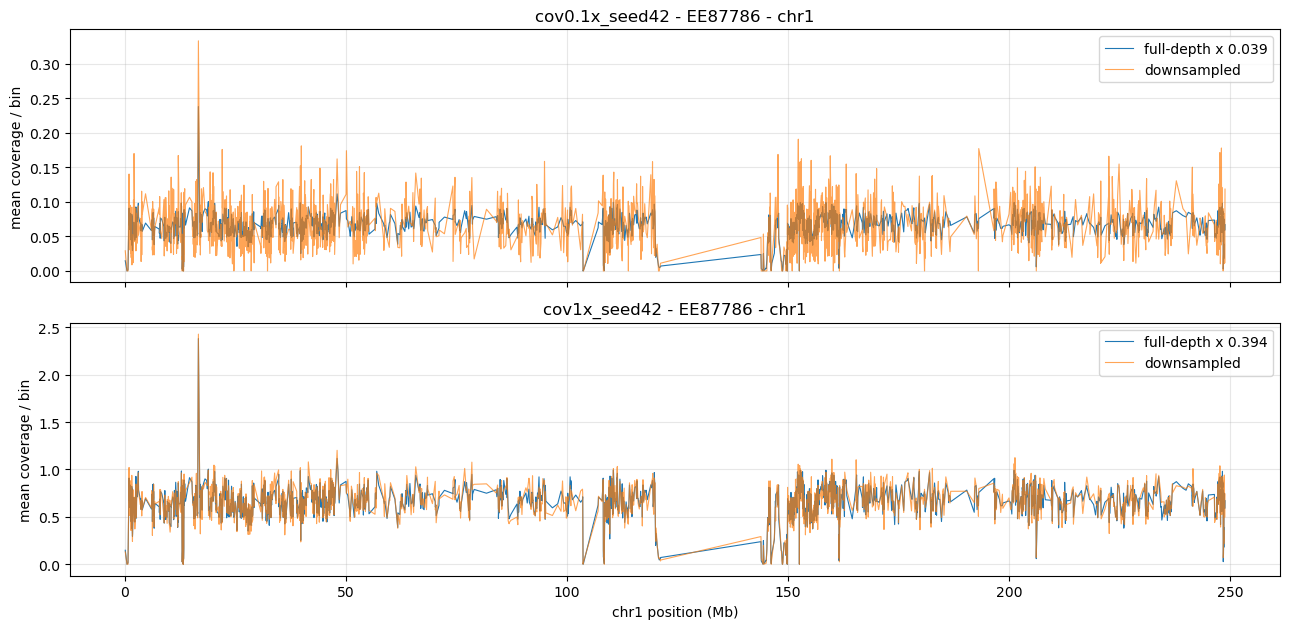

In [5]:
if runs:
    sample0 = None
    fig, axes = plt.subplots(len(data), 1, figsize=(13, 3.2 * len(data)), squeeze=False, sharex=True)
    for i, (run_name, samples) in enumerate(data.items()):
        sample = sample0 or next(iter(samples))
        sample0 = sample if sample in samples else sample0
        d = samples.get(sample) or next(iter(samples.values()))
        full, ds, f = d["full"], d["ds"], d["frac"]
        sel_full = full[full["chrom"] == PROFILE_CHROM].sort_values("start")
        sel_ds = ds[ds["chrom"] == PROFILE_CHROM].sort_values("start")
        x = sel_full["start"].values / 1e6
        ax = axes[i][0]
        ax.plot(x, f * sel_full["mean_coverage"].values, lw=0.8, label=f"full-depth x {f:.3f}")
        ax.plot(x, sel_ds["mean_coverage"].values, lw=0.8, alpha=0.7, label="downsampled")
        ax.set_ylabel("mean coverage / bin")
        ax.set_title(f"{run_name} - {sample} - {PROFILE_CHROM}")
        ax.legend(loc="upper right"); ax.grid(alpha=0.3)
    axes[-1][0].set_xlabel(f"{PROFILE_CHROM} position (Mb)")
    plt.tight_layout(); plt.show()


## Check 4 — fragment-length distribution is preserved

Hash thinning must be blind to fragment properties. Comparing the *normalized*
fragment-length distributions (summed over all bins): full vs downsampled curves should
be indistinguishable; the largest per-length deviation is reported per sample. The raw
(unnormalized) inset confirms the vertical scaling by the keep-fraction.


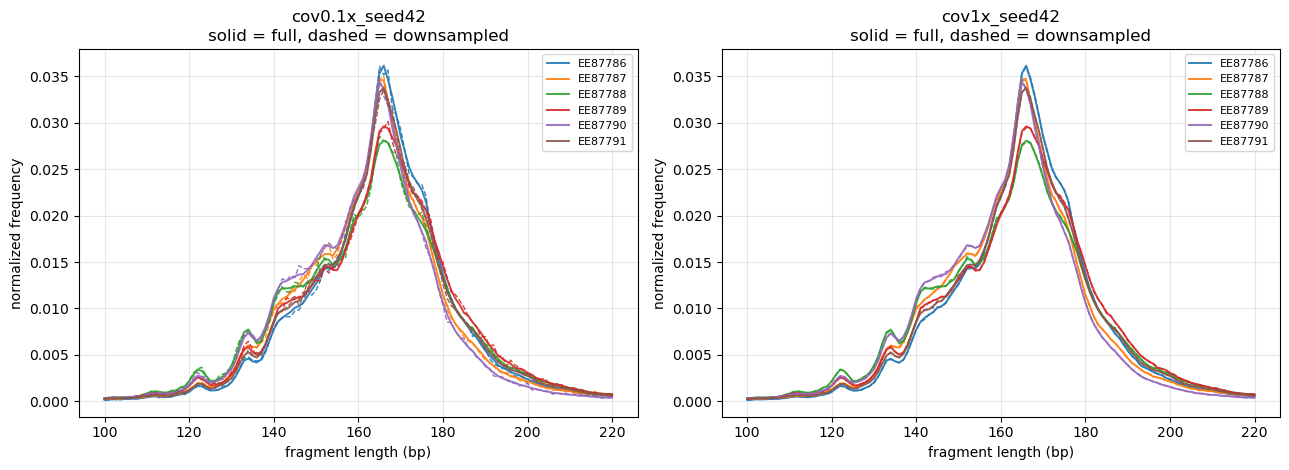

           run  sample  max_abs_dev  short_long_ratio_full  short_long_ratio_ds
cov0.1x_seed42 EE87786      0.00114                0.21143              0.21028
cov0.1x_seed42 EE87787      0.00104                0.28234              0.27938
cov0.1x_seed42 EE87788      0.00116                0.32448              0.32251
cov0.1x_seed42 EE87789      0.00107                0.26044              0.26405
cov0.1x_seed42 EE87790      0.00140                0.33205              0.33836
cov0.1x_seed42 EE87791      0.00102                0.23978              0.24278
  cov1x_seed42 EE87786      0.00029                0.21143              0.21130
  cov1x_seed42 EE87787      0.00032                0.28234              0.28241
  cov1x_seed42 EE87788      0.00024                0.32448              0.32424
  cov1x_seed42 EE87789      0.00030                0.26044              0.26034
  cov1x_seed42 EE87790      0.00038                0.33205              0.33257
  cov1x_seed42 EE87791      0.00030     

In [6]:
if runs:
    lengths = np.array([int(c) for c in LEN_COLS])
    fig, axes = plt.subplots(1, len(data), figsize=(6.5 * len(data), 4.8), squeeze=False)
    rows = []
    for i, (run_name, samples) in enumerate(data.items()):
        ax = axes[0][i]
        for sample, d in samples.items():
            full_hist = d["full"][LEN_COLS].sum(axis=0).values
            ds_hist = d["ds"][LEN_COLS].sum(axis=0).values
            full_p = full_hist / full_hist.sum()
            ds_p = ds_hist / ds_hist.sum()
            rows.append({"run": run_name, "sample": sample,
                         "max_abs_dev": np.abs(full_p - ds_p).max(),
                         "short_long_ratio_full": d["full"]["absolute_short_fragments"].sum() / d["full"]["absolute_long_fragments"].sum(),
                         "short_long_ratio_ds": d["ds"]["absolute_short_fragments"].sum() / d["ds"]["absolute_long_fragments"].sum()})
            line, = ax.plot(lengths, full_p, lw=1.4, alpha=0.9, label=sample)
            ax.plot(lengths, ds_p, lw=1.0, ls="--", color=line.get_color(), alpha=0.9)
        ax.set_title(f"{run_name}\nsolid = full, dashed = downsampled")
        ax.set_xlabel("fragment length (bp)"); ax.set_ylabel("normalized frequency")
        ax.legend(fontsize=8); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    check4 = pd.DataFrame(rows)
    print(check4.to_string(index=False, float_format=lambda v: f"{v:.5f}"))
    worst = check4["max_abs_dev"].max()
    print(f"\nWorst per-length deviation: {worst:.5f} "
          f"({'OK - length-unbiased' if worst < 0.005 else 'INVESTIGATE - possible length bias'})")


## Check 5 — per-TSS model metrics: downsampled vs full depth

Per-locus scatter of each classifier feature (downsampled vs full depth), pooled over
all loaded samples. Rows = downsampling runs, columns = the five model features. Each
panel is annotated with the pooled Pearson *r* and the median per-sample Pearson *r*.

Expectation: at ~1x (keep-fraction ≈ 0.3–0.4 of native ~2.9x) the cloud hugs the
identity line; at 0.1x it is visibly wider — depth-driven noise, not a simulation
artifact. A *tilted* or *offset* cloud (regression away from the identity line beyond
the shrinkage that extra noise in sparse bins produces) would indicate bias.

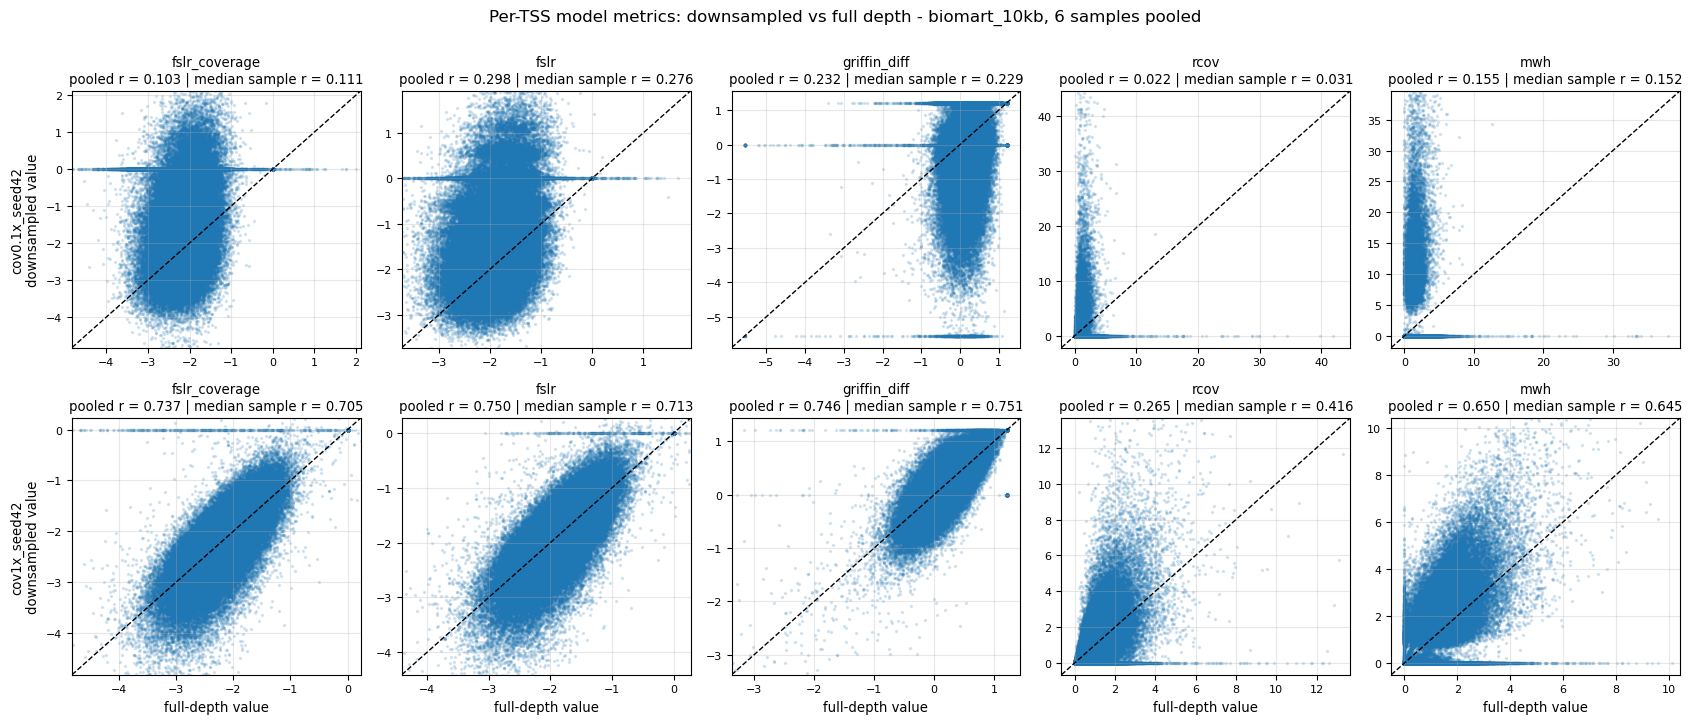

In [7]:
def paired_feature_values(d, col):
    """Aligned (full, downsampled) per-bin values with NaNs removed pairwise."""
    x = d["full"][col].to_numpy(dtype=float)
    y = d["ds"][col].to_numpy(dtype=float)
    ok = np.isfinite(x) & np.isfinite(y)
    return x[ok], y[ok]


if runs:
    fig, axes = plt.subplots(len(data), len(FEATURE_COLS),
                             figsize=(3.4 * len(FEATURE_COLS), 3.6 * len(data)),
                             squeeze=False)
    for i, (run_name, samples) in enumerate(data.items()):
        for j, col in enumerate(FEATURE_COLS):
            ax = axes[i][j]
            xs, ys, per_sample_r = [], [], []
            for sample, d in samples.items():
                x, y = paired_feature_values(d, col)
                xs.append(x); ys.append(y)
                if len(x) > 2 and np.std(x) > 0 and np.std(y) > 0:
                    per_sample_r.append(np.corrcoef(x, y)[0, 1])
            x = np.concatenate(xs); y = np.concatenate(ys)
            pooled_r = np.corrcoef(x, y)[0, 1]

            ax.scatter(x, y, s=2, alpha=0.15, rasterized=True, color="C0")
            lo, hi = np.nanpercentile(np.concatenate([x, y]), [0.1, 99.9])
            pad = 0.05 * (hi - lo) if hi > lo else 1.0
            lo, hi = lo - pad, hi + pad
            ax.plot([lo, hi], [lo, hi], "k--", lw=1)
            ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
            ax.set_title(f"{col}\npooled r = {pooled_r:.3f} | median sample r = {np.median(per_sample_r):.3f}",
                         fontsize=9.5)
            if j == 0:
                ax.set_ylabel(f"{run_name}\ndownsampled value", fontsize=9.5)
            if i == len(data) - 1:
                ax.set_xlabel("full-depth value", fontsize=9.5)
            ax.grid(alpha=0.3)
            ax.tick_params(labelsize=8)
    fig.suptitle(f"Per-TSS model metrics: downsampled vs full depth - {BED_NAME}, "
                 f"{len(next(iter(data.values())))} samples pooled", y=1.0)
    plt.tight_layout(); plt.show()

## Check 6 — per-sample metric preservation across depths

Pearson correlation between full-depth and downsampled per-TSS values, computed per
sample, for every feature and run. One marker per sample; the bar is the median.
This is the per-sample version of check 5: it shows whether metric preservation is
uniform across samples or driven by outliers (e.g. samples with native coverage close
to the target, whose keep-fraction is ~1 and whose correlation must be ~1).

The table also reports Spearman ρ (rank agreement, robust to the heavy tails of
`fslr`-type log-ratios) and the sample's keep-fraction.

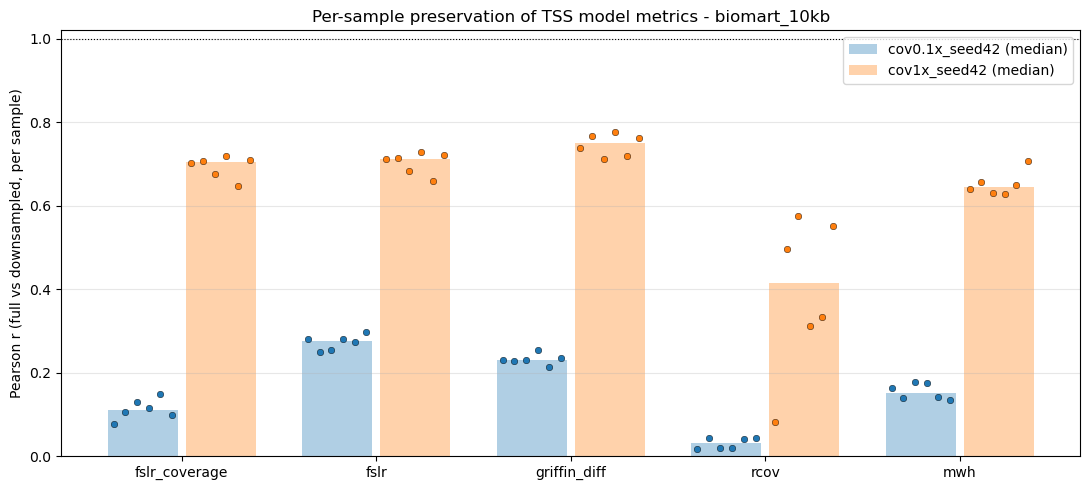

                              median_pearson  min_pearson  median_spearman  min_spearman
run            feature                                                                  
cov0.1x_seed42 fslr_coverage           0.111        0.076            0.081         0.037
               fslr                    0.276        0.249            0.264         0.241
               griffin_diff            0.229        0.213            0.247         0.237
               rcov                    0.031        0.016            0.170         0.157
               mwh                     0.152        0.135            0.188         0.174
cov1x_seed42   fslr_coverage           0.705        0.646            0.684         0.639
               fslr                    0.713        0.658            0.686         0.646
               griffin_diff            0.751        0.711            0.738         0.702
               rcov                    0.416        0.082            0.665         0.612
               mwh   

In [8]:
if runs:
    from scipy.stats import spearmanr

    rows = []
    for run_name, samples in data.items():
        for sample, d in samples.items():
            for col in FEATURE_COLS:
                x, y = paired_feature_values(d, col)
                pear = np.corrcoef(x, y)[0, 1] if np.std(x) > 0 and np.std(y) > 0 else np.nan
                spear = spearmanr(x, y).statistic if len(x) > 2 else np.nan
                rows.append({"run": run_name, "sample": sample, "feature": col,
                             "keep_frac": d["frac"], "pearson_r": pear, "spearman_rho": spear})
    check6 = pd.DataFrame(rows)

    fig, ax = plt.subplots(figsize=(11, 5))
    run_names = list(data)
    n_runs = len(run_names)
    width = 0.8 / n_runs
    xbase = np.arange(len(FEATURE_COLS))
    for k, run_name in enumerate(run_names):
        off = (k - (n_runs - 1) / 2) * width
        sub = check6[check6["run"] == run_name]
        med = sub.groupby("feature")["pearson_r"].median().reindex(FEATURE_COLS)
        ax.bar(xbase + off, med.values, width * 0.9, alpha=0.35, color=f"C{k}",
               label=f"{run_name} (median)")
        for j, col in enumerate(FEATURE_COLS):
            vals = sub[sub["feature"] == col]["pearson_r"].values
            jitter = (np.arange(len(vals)) - (len(vals) - 1) / 2) * (width * 0.15)
            ax.scatter(np.full(len(vals), xbase[j] + off) + jitter, vals,
                       s=22, color=f"C{k}", edgecolor="k", linewidth=0.3, zorder=3)
    ax.set_xticks(xbase); ax.set_xticklabels(FEATURE_COLS)
    ax.set_ylabel("Pearson r (full vs downsampled, per sample)")
    ax.set_ylim(0, 1.02)
    ax.axhline(1.0, color="k", lw=0.8, ls=":")
    ax.set_title(f"Per-sample preservation of TSS model metrics - {BED_NAME}")
    ax.legend(); ax.grid(alpha=0.3, axis="y")
    plt.tight_layout(); plt.show()

    summary6 = (check6.groupby(["run", "feature"])
                .agg(median_pearson=("pearson_r", "median"), min_pearson=("pearson_r", "min"),
                     median_spearman=("spearman_rho", "median"), min_spearman=("spearman_rho", "min"))
                .reindex(pd.MultiIndex.from_product([run_names, FEATURE_COLS],
                                                    names=["run", "feature"])))
    print(summary6.to_string(float_format=lambda v: f"{v:.3f}"))

## Check 7 — do the metric *distributions* shift at lower depth?

Correlation (checks 5–6) can stay high while the whole distribution drifts. For each
feature: the empirical CDF of pooled per-TSS values at full depth vs the two
downsampled depths, plus a table of the distribution moments and the fraction of
*degenerate* bins (exact zeros — `rcov`/`mwh` fall back to 0 when a bin has too few
fragments to compute the metric, and `fslr`-type log-ratios hit their pseudocount
floor).

Zero-inflation and wider spread at 0.1x are genuine shallow-sequencing behaviour and
feed directly into interpreting the downsampled model performance: they quantify how
much per-locus signal the classifier still has to work with at each depth.

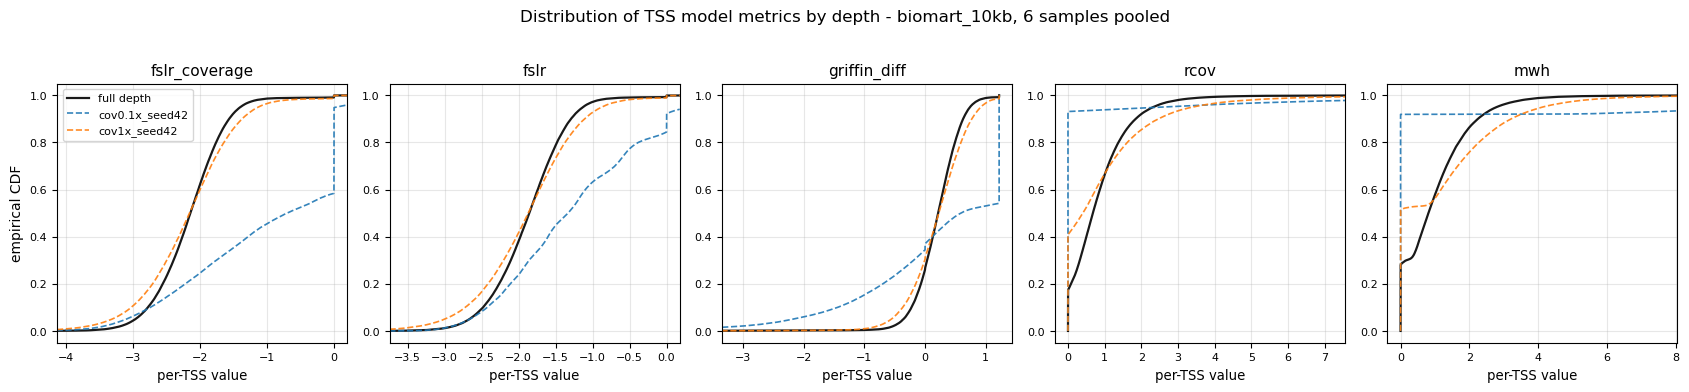

                                mean      sd  median  frac_zero
feature       depth                                            
fslr_coverage full depth     -2.1505  0.5190 -2.1465     0.0092
              cov0.1x_seed42 -1.0171  1.1961 -0.7017     0.3639
              cov1x_seed42   -2.1760  0.6986 -2.1583     0.0130
fslr          full depth     -1.8658  0.4932 -1.8552     0.0069
              cov0.1x_seed42 -1.2457  0.9574 -1.3323     0.0778
              cov1x_seed42   -1.8925  0.6639 -1.8697     0.0097
griffin_diff  full depth      0.2013  0.3877  0.2146     0.0054
              cov0.1x_seed42  0.2285  1.2433  0.5877     0.0257
              cov1x_seed42    0.2034  0.4858  0.2256     0.0072
rcov          full depth      0.8562  1.8980  0.6783     0.1738
              cov0.1x_seed42  0.7634 13.5749  0.0000     0.9314
              cov1x_seed42    0.9433  2.6816  0.4051     0.4091
mwh           full depth      0.9874  1.1631  0.8078     0.2794
              cov0.1x_seed42  1.1891  4.

In [9]:
if runs:
    # Pool per-TSS values over the loaded samples: full depth once, plus each run.
    first_run = next(iter(data))
    pools = {"full depth": {col: np.concatenate([
        d["full"][col].to_numpy(dtype=float)[np.isfinite(d["full"][col].to_numpy(dtype=float))]
        for d in data[first_run].values()]) for col in FEATURE_COLS}}
    for run_name, samples in data.items():
        pools[run_name] = {col: np.concatenate([
            d["ds"][col].to_numpy(dtype=float)[np.isfinite(d["ds"][col].to_numpy(dtype=float))]
            for d in samples.values()]) for col in FEATURE_COLS}

    fig, axes = plt.subplots(1, len(FEATURE_COLS), figsize=(3.4 * len(FEATURE_COLS), 3.8),
                             squeeze=False)
    rows = []
    for j, col in enumerate(FEATURE_COLS):
        ax = axes[0][j]
        for k, (depth_name, vals_by_col) in enumerate(pools.items()):
            v = np.sort(vals_by_col[col])
            ax.plot(v, np.arange(1, len(v) + 1) / len(v),
                    lw=1.6 if depth_name == "full depth" else 1.2,
                    color="k" if depth_name == "full depth" else f"C{k - 1}",
                    ls="-" if depth_name == "full depth" else "--",
                    label=depth_name, alpha=0.9)
            rows.append({"feature": col, "depth": depth_name, "mean": v.mean(),
                         "sd": v.std(), "median": np.median(v),
                         "frac_zero": float(np.mean(v == 0.0))})
        lo, hi = np.nanpercentile(pools["full depth"][col], [0.1, 99.9])
        span = hi - lo if hi > lo else 1.0
        ax.set_xlim(lo - 0.05 * span, hi + 0.05 * span)
        ax.set_title(col, fontsize=11)
        ax.set_xlabel("per-TSS value", fontsize=9.5)
        if j == 0:
            ax.set_ylabel("empirical CDF")
            ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
        ax.tick_params(labelsize=8)
    fig.suptitle(f"Distribution of TSS model metrics by depth - {BED_NAME}, "
                 f"{len(data[first_run])} samples pooled", y=1.02)
    plt.tight_layout(); plt.show()

    check7 = pd.DataFrame(rows).set_index(["feature", "depth"])
    print(check7.to_string(float_format=lambda v: f"{v:.4f}"))

## What passing looks like

* Check 1: all points on the identity line, |relative error| well under 1%.
* Check 2: tight identity scatter; residual band flat, spread ~1, no chromosome blocks.
* Check 3: traces coincide after scaling; downsampled trace only noisier.
* Check 4: dashed and solid curves indistinguishable; short/long ratios match.
* Check 5: clouds centered on the identity line — wider at 0.1x than at 1x, but not
  tilted or offset.
* Check 6: per-sample correlations tightly grouped per feature/run; cov1x well above
  cov0.1x for every feature; no single-sample outliers (except keep-fraction ≈ 1
  samples, which must sit at r ≈ 1).
* Check 7: CDFs at 1x nearly coincide with full depth; at 0.1x wider spread and more
  exact zeros are expected — what matters is that the shift is explainable by depth
  (sparse bins going degenerate), not a wholesale relocation of the distribution.

Together these confirm the thinning is file-wide and property-blind — equivalent to
having sequenced the library at the target depth — so differences in downstream model
performance (see `src/figures/figS8.ipynb` for the model-level comparison) can be
attributed to depth, not to an artifact of the simulation.